# 2.1.1

## Análise do conj de dados

In [1]:
import pandas as pd

# Carregar o ficheiro CSV
df_test = pd.read_csv('data/amazon_reviews_test.csv')

# Exibir as primeiras linhas
display(df_test.head())



,sentiment,review
0,negative,I was going to give these seeds a 3-star ratin...
1,positive,"This is a nice smooth coffee, a part of the Ke..."
2,positive,I order this pearl sugar to make liege waffle....
3,negative,Used these in a waffle recipe that said they w...
4,positive,"Mayonnaise is an interesting product, cool, sm..."


In [2]:
# Carregar o ficheiro CSV
df_train = pd.read_csv('data/amazon_reviews_train.csv')

# Exibir as primeiras linhas
display(df_train.head())


,sentiment,review
0,negative,Product arrived labeled as Jumbo Salted Peanut...
1,positive,This is a confection that has been around a fe...
2,negative,If you are looking for the secret ingredient i...
3,positive,Great taffy at a great price. There was a wid...
4,positive,This saltwater taffy had great flavors and was...


In [3]:
# Verificar valores nulos
null_counts = df_test.isnull().sum()
print("Valores nulos por coluna teste:")
display(null_counts)

# Verificar valores nulos
null_counts = df_train.isnull().sum()
print("Valores nulos por coluna treino:")
display(null_counts)

Valores nulos por coluna teste:


sentiment    0
review       0
dtype: int64

Valores nulos por coluna treino:


sentiment    0
review       0
dtype: int64

In [4]:
print("Distribuição original dos sentimentos (teste):")
display(df_test['sentiment'].value_counts())

# Comparação percentual
print("\nPercentagem original:")
display(df_test['sentiment'].value_counts(normalize=True) * 100)

Distribuição original dos sentimentos (teste):


sentiment
positive    1676
negative     741
Name: count, dtype: int64


Percentagem original:


sentiment
positive    69.34216
negative    30.65784
Name: proportion, dtype: float64

In [5]:
print("Distribuição original dos sentimentos (treino):")
display(df_train['sentiment'].value_counts())

# Comparação percentual
print("\nPercentagem original:")
display(df_train['sentiment'].value_counts(normalize=True) * 100)

Distribuição original dos sentimentos (treino):


sentiment
positive    37835
negative    11067
Name: count, dtype: int64


Percentagem original:


sentiment
positive    77.369024
negative    22.630976
Name: proportion, dtype: float64

## Limpeza de Dados para TextBlob
O TextBlob utiliza um léxico onde a polaridade é atribuída a palavras e frases. Vamos remover URLs e caracteres especiais, mas manter a capitalização original pode ser útil se decidires usar outros modelos depois.

In [9]:
%pip install textblob

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [ ]:
from textblob import TextBlob
import re
def clean_for_textblob(text):
    # Remover URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # Remover HTML
    text = re.sub(r'<[^>]+>', ' ', text)
    # Remover menções e hashtags
    text = re.sub(r'@[A-Za-z0-9_]+|#[A-Za-z0-9_]+', '', text)
    # Remover caracteres especiais mantendo apenas letras e espaços (limpeza moderada)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # Remover espaços extras
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Aplicar a limpeza
df_test['review_textblob'] = df_test['review'].apply(clean_for_textblob)


In [102]:
def get_sentiment(text):
    blob = TextBlob(text)
    return blob.sentiment.polarity, blob.sentiment.subjectivity

# Aplicar a função a todo o dataset e descompactar os resultados em novas colunas
df_test[['polarity', 'subjectivity']] = df_test['review_textblob'].apply(lambda x: pd.Series(get_sentiment(x)))

# Exibir as primeiras linhas para conferir os resultados
display(df_test[['review', 'sentiment', 'polarity', 'subjectivity']].head())

,review,sentiment,polarity,subjectivity
0,I was going to give these seeds a 3-star ratin...,negative,0.125000,0.594676
1,"This is a nice smooth coffee, a part of the Ke...",positive,0.190278,0.721296
2,I order this pearl sugar to make liege waffle....,positive,0.032143,0.302143
3,Used these in a waffle recipe that said they w...,negative,-0.187143,0.784286
4,"Mayonnaise is an interesting product, cool, sm...",positive,0.106909,0.583697


In [103]:
zero_polarity_count = (df_test['polarity'] == 0).sum()
print(f"Quantidade de reviews com polaridade zero: {zero_polarity_count}")
print(f"Percentagem: {(zero_polarity_count / len(df_test)) * 100:.2f}%")

Quantidade de reviews com polaridade zero: 42
Percentagem: 1.74%


In [104]:
# Converter polaridade em rótulo (considerando 0 como negativo)
df_test['pred_sentiment'] = df_test['polarity'].apply(lambda x: 'positive' if x > 0 else 'negative')

# Visualizar a distribuição dos novos rótulos
print("Distribuição das previsões:")
display(df_test['pred_sentiment'].value_counts())

# Mostrar exemplo das reviews que eram 0
display(df_test[df_test['polarity'] == 0][['review', 'polarity', 'pred_sentiment']].head())

Distribuição das previsões:


pred_sentiment
positive    2023
negative     394
Name: count, dtype: int64

,review,polarity,pred_sentiment
20,I have been taking this for six weeks. I have...,0.0,negative
91,"My three dogs like it a lot, and my problem do...",0.0,negative
105,"For colombian ground coffee lovers , this is a...",0.0,negative
161,Splenda is Splenda. The quantity for the pric...,0.0,negative
165,Es la segunda vez que compro con este proveedo...,0.0,negative


In [105]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Métricas por Classe
print("Métricas detalhadas por classe:")
print(classification_report(df_test['sentiment'], df_test['pred_sentiment']))

# Matriz de Confusão para visualizar erros e acertos
cm = confusion_matrix(df_test['sentiment'], df_test['pred_sentiment'], labels=['positive', 'negative'])
print("Matriz de Confusão:")
print(f"Positivos reais classificados como positivos: {cm[0][0]}")
print(f"Positivos reais classificados como negativos: {cm[0][1]}")
print(f"Negativos reais classificados como negativos: {cm[1][1]}")
print(f"Negativos reais classificados como positivos: {cm[1][0]}")

Métricas detalhadas por classe:
              precision    recall  f1-score   support

    negative       0.74      0.39      0.51       741
    positive       0.78      0.94      0.85      1676

    accuracy                           0.77      2417
   macro avg       0.76      0.67      0.68      2417
weighted avg       0.77      0.77      0.75      2417

Matriz de Confusão:
Positivos reais classificados como positivos: 1574
Positivos reais classificados como negativos: 102
Negativos reais classificados como negativos: 292
Negativos reais classificados como positivos: 449


## Limpeza de Dados para VADER

O VADER (Valence Aware Dictionary and sEntiment Reasoner) é um modelo de análise de sentimento baseado em léxico que se beneficia da presença de pontuação, capitalização e até emojis para inferir a intensidade do sentimento. Portanto, a limpeza para o VADER deve ser menos agressiva, focando principalmente na remoção de URLs e menções, mas mantendo a estrutura do texto o máximo possível.

In [94]:
import re

def clean_for_vader(text):
    # Remover URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # Remover tags HTML (como <br />, <div>, etc.) 
    text = re.sub(r'<[^>]+>', ' ', text)
    # Remover menções e hashtags 
    text = re.sub(r'@[A-Za-z0-9_]+|#[A-Za-z0-9_]+', '', text)
    # Remover espaços extras, mas manter outros caracteres e pontuações
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Aplicar a limpeza
df_test['review_vader'] = df_test['review'].apply(clean_for_vader)

# Exibir as primeiras linhas para conferir os resultados
display(df_test[['review', 'review_vader', 'sentiment']].head())

,review,review_vader,sentiment
0,I was going to give these seeds a 3-star ratin...,I was going to give these seeds a 3-star ratin...,negative
1,"This is a nice smooth coffee, a part of the Ke...","This is a nice smooth coffee, a part of the Ke...",positive
2,I order this pearl sugar to make liege waffle....,I order this pearl sugar to make liege waffle....,positive
3,Used these in a waffle recipe that said they w...,Used these in a waffle recipe that said they w...,negative
4,"Mayonnaise is an interesting product, cool, sm...","Mayonnaise is an interesting product, cool, sm...",positive


In [16]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [95]:
import nltk
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [96]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Inicializar o analisador de sentimentos VADER
sia = SentimentIntensityAnalyzer()

def get_vader_sentiment(text):
    return sia.polarity_scores(text)['compound']

df_test['vader_polarity'] = df_test['review_vader'].apply(get_vader_sentiment)

# Exibir as primeiras linhas com a nova coluna de polaridade VADER
display(df_test[['review', 'sentiment', 'review_vader', 'vader_polarity']].head())

,review,sentiment,review_vader,vader_polarity
0,I was going to give these seeds a 3-star ratin...,negative,I was going to give these seeds a 3-star ratin...,-0.8307
1,"This is a nice smooth coffee, a part of the Ke...",positive,"This is a nice smooth coffee, a part of the Ke...",0.1579
2,I order this pearl sugar to make liege waffle....,positive,I order this pearl sugar to make liege waffle....,0.5499
3,Used these in a waffle recipe that said they w...,negative,Used these in a waffle recipe that said they w...,-0.6079
4,"Mayonnaise is an interesting product, cool, sm...",positive,"Mayonnaise is an interesting product, cool, sm...",0.9726


In [97]:
# Converter a polaridade VADER em rótulo de sentimento (adaptado para rótulos binários)
df_test['vader_pred_sentiment'] = df_test['vader_polarity'].apply(lambda x: 'positive' if x > 0 else 'negative')

# Visualizar a distribuição dos novos rótulos
print("Distribuição das previsões VADER:")
display(df_test['vader_pred_sentiment'].value_counts())

# Mostrar exemplos de reviews com polaridade zero pelo VADER
print("\nExemplos de reviews com polaridade VADER zero:")
display(df_test[df_test['vader_polarity'] == 0][['review', 'sentiment', 'vader_polarity', 'vader_pred_sentiment']].head())

Distribuição das previsões VADER:


vader_pred_sentiment
positive    1998
negative     419
Name: count, dtype: int64


Exemplos de reviews com polaridade VADER zero:


,review,sentiment,vader_polarity,vader_pred_sentiment
161,Splenda is Splenda. The quantity for the pric...,positive,0.0,negative
326,You can buy this product at costco for 6.00 an...,negative,0.0,negative
339,As a previous reader commented this product do...,negative,0.0,negative
353,"These are portable, fruit only, and they are i...",positive,0.0,negative
462,"This product states on the label ""Fructose FRU...",negative,0.0,negative


In [98]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# Métricas por Classe
print("Métricas detalhadas por classe (VADER):")
print(classification_report(df_test['sentiment'], df_test['vader_pred_sentiment']))

# Matriz de Confusão para visualizar erros e acertos
cm_vader = confusion_matrix(df_test['sentiment'], df_test['vader_pred_sentiment'], labels=['positive', 'negative'])
print("Matriz de Confusão (VADER):")
print(f"Positivos reais classificados como positivos: {cm_vader[0][0]}")
print(f"Positivos reais classificados como negativos: {cm_vader[0][1]}")
print(f"Negativos reais classificados como negativos: {cm_vader[1][1]}")
print(f"Negativos reais classificados como positivos: {cm_vader[1][0]}")

Métricas detalhadas por classe (VADER):
              precision    recall  f1-score   support

    negative       0.78      0.44      0.57       741
    positive       0.79      0.95      0.86      1676

    accuracy                           0.79      2417
   macro avg       0.79      0.69      0.71      2417
weighted avg       0.79      0.79      0.77      2417

Matriz de Confusão (VADER):
Positivos reais classificados como positivos: 1585
Positivos reais classificados como negativos: 91
Negativos reais classificados como negativos: 328
Negativos reais classificados como positivos: 413


## Análise de Sentimentos com Stanza

O Stanza é uma biblioteca de processamento de linguagem natural da Stanford University, que oferece modelos pré-treinados para várias tarefas, incluindo análise de sentimentos. É mais robusto que o TextBlob e o VADER, pois utiliza modelos neurais de aprendizado de máquina.

### Instalação e Download do Modelo

In [21]:
%pip install stanza

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [22]:
# Instalar Stanza (se ainda não estiver instalado)

import torch
import stanza

# 1. Check PyTorch
print(f"PyTorch version: {torch.__version__}")
print(f"Is CUDA (GPU) available? {torch.cuda.is_available()}")
print(f"Device Name: {torch.cuda.get_device_name(0)}")

# 2. Check Stanza
# This will now say "Using device: cuda" in the logs
nlp_stanza = stanza.Pipeline(lang='en', processors='tokenize,mwt,sentiment', use_gpu=True)


~\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-04-23 11:34:54 INFO: Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


PyTorch version: 2.11.0+cu126
Is CUDA (GPU) available? True
Device Name: NVIDIA GeForce RTX 4060 Ti


2026-04-23 11:34:54 INFO: Downloaded file to ~\AppData\Local\StanfordNLP\stanza\Cache\1.11.0\resources\resources.json
2026-04-23 11:34:55 INFO: Loading these models for language: en (English):
| Processor | Package        |
------------------------------
| tokenize  | combined       |
| mwt       | combined       |
| sentiment | sstplus_charlm |

2026-04-23 11:34:55 INFO: Using device: cuda
2026-04-23 11:34:55 INFO: Loading: tokenize
2026-04-23 11:34:58 INFO: Loading: mwt
2026-04-23 11:34:58 INFO: Loading: sentiment
2026-04-23 11:35:00 INFO: Done loading processors!


### Limpeza de Dados para Stanza

Para o Stanza, a limpeza de dados pode ser semelhante à do VADER, focando na remoção de URLs e menções, mas mantendo a estrutura original do texto tanto quanto possível, já que ele é projetado para lidar com texto em linguagem natural.

In [99]:
import re

def clean_for_stanza(text):
    # Remover URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # Remover tags HTML (como <br />, <div>, etc.) 
    text = re.sub(r'<[^>]+>', ' ', text)
    # Remover menções e hashtags
    text = re.sub(r'@[A-Za-z0-9_]+|#[A-Za-z0-9_]+', '', text)
    # Remover espaços extras
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Aplicar a limpeza
df_test['review_stanza'] = df_test['review'].apply(clean_for_stanza)

# Exibir as primeiras linhas para conferir os resultados
display(df_test[['review', 'review_stanza', 'sentiment']].head())



,review,review_stanza,sentiment
0,I was going to give these seeds a 3-star ratin...,I was going to give these seeds a 3-star ratin...,negative
1,"This is a nice smooth coffee, a part of the Ke...","This is a nice smooth coffee, a part of the Ke...",positive
2,I order this pearl sugar to make liege waffle....,I order this pearl sugar to make liege waffle....,positive
3,Used these in a waffle recipe that said they w...,Used these in a waffle recipe that said they w...,negative
4,"Mayonnaise is an interesting product, cool, sm...","Mayonnaise is an interesting product, cool, sm...",positive


### Aplicação do Stanza para Análise de Sentimentos

O Stanza retorna 0 para negativo, 1 para neutro e 2 para positivo. Como temos apenas rótulos binários ('positive', 'negative'), vamos mapear 0 para 'negative' e 1 e 2 para 'positive'.

In [100]:
from tqdm.auto import tqdm

# 1. Prepare data - ensuring everything is a string to avoid errors
reviews = df_test['review_stanza'].astype(str).tolist()
all_sentiments = []

print(f"Starting GPU-accelerated processing for {len(reviews)} rows...")

# 2. Process each review individually (Simple & Safe)
# The speedup comes from nlp_stanza being on 'cuda'
for text in tqdm(reviews, desc="Analyzing Sentiment"):
    # Run the model on the single text
    doc = nlp_stanza(text)
    
    # Extract the sentiment of the first sentence
    # If no sentences are found (empty text), default to 1 (neutral)
    if doc.sentences:
        all_sentiments.append(doc.sentences[0].sentiment)
    else:
        all_sentiments.append(1)

# 3. Add results to the DataFrame
df_test['stanza_polarity'] = all_sentiments

# 4. Map the numeric scores to 'positive' or 'negative'
# Note: Stanza is 0:Neg, 1:Neu, 2:Pos. This logic maps 0 and 1 to negative.
df_test['stanza_pred_sentiment'] = df_test['stanza_polarity'].apply(
    lambda x: 'positive' if x == 2 else 'negative'
)

print("\nProcessing Complete!")

Starting GPU-accelerated processing for 2417 rows...


Analyzing Sentiment: 100%|██████████| 2417/2417 [01:22<00:00, 29.19it/s]


Processing Complete!


### Avaliação do Desempenho do Stanza

In [25]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Métricas por Classe
print("Métricas detalhadas por classe (Stanza):")
print(classification_report(df_test['sentiment'], df_test['stanza_pred_sentiment']))

# Matriz de Confusão para visualizar erros e acertos
cm_stanza = confusion_matrix(df_test['sentiment'], df_test['stanza_pred_sentiment'], labels=['positive', 'negative'])
print("Matriz de Confusão (Stanza):")
print(f"Positivos reais classificados como positivos: {cm_stanza[0][0]}")
print(f"Positivos reais classificados como negativos: {cm_stanza[0][1]}")
print(f"Negativos reais classificados como negativos: {cm_stanza[1][1]}")
print(f"Negativos reais classificados como positivos: {cm_stanza[1][0]}")

Métricas detalhadas por classe (Stanza):
              precision    recall  f1-score   support

    negative       0.44      0.82      0.57       741
    positive       0.87      0.54      0.67      1676

    accuracy                           0.63      2417
   macro avg       0.66      0.68      0.62      2417
weighted avg       0.74      0.63      0.64      2417

Matriz de Confusão (Stanza):
Positivos reais classificados como positivos: 912
Positivos reais classificados como negativos: 764
Negativos reais classificados como negativos: 604
Negativos reais classificados como positivos: 137


# 2.1.2

## DistilBERT

In [26]:
%pip install transformers

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [27]:
import pandas as pd
from transformers import pipeline
from tqdm import tqdm

# 1. Carregar o pipeline de Sentiment Analysis
# Ele já descarrega o distilbert-base-uncased-finetuned-sst-2-english por defeito
model_name = "distilbert-base-uncased-finetuned-sst-2-english"
classifier = pipeline("sentiment-analysis", model=model_name, device=0) # device=0 para usar GPU se disponível

# 2. Função simples de limpeza
def clean_text(text):
    import re
    text = re.sub(r'<.*?>', '', text) # Remove HTML
    text = re.sub(r'http\S+', '', text) # Remove URLs
    return text.strip()

# Aplicar limpeza
df_test['review_bert'] = df_test['review'].apply(clean_text)

# 3. Inferência (Processamento em massa)
# Dica: Passar listas para o classifier é mais rápido que um loop por linha
texts = df_test['review_bert'].tolist()

# O BERT tem um limite de 512 tokens. Reviews muito longas devem ser truncadas.
results = classifier(texts, truncation=True, padding=True)

# 4. Extrair resultados
df_test['pred_label'] = [res['label'].lower() for res in results]
df_test['confidence'] = [res['score'] for res in results]



Loading weights: 100%|██████████| 104/104 [00:00<00:00, 6134.27it/s]


In [28]:
# 5. Avaliação (Comparar com as tuas tags originais)
from sklearn.metrics import classification_report
print(classification_report(df_test['sentiment'], df_test['pred_label']))

# 6. Matriz de Confusão
# Mantemos a ordem das labels que já definiam para garantir a comparação direta
cm = confusion_matrix(df_test['sentiment'], df_test['pred_label'], labels=['positive', 'negative'])

print("Matriz de Confusão:")
print(f"Positivos reais classificados como positivos (TP): {cm[0][0]}")
print(f"Positivos reais classificados como negativos (FN): {cm[0][1]}")
print(f"Negativos reais classificados como negativos (TN): {cm[1][1]}")
print(f"Negativos reais classificados como positivos (FP): {cm[1][0]}")

# Dica extra: Cálculo da Accuracy global para comparação rápida
acc = accuracy_score(df_test['sentiment'], df_test['pred_label'])
print(f"\nAccuracy Final do DistilBERT: {acc:.2%}")

              precision    recall  f1-score   support

    negative       0.65      0.91      0.76       741
    positive       0.95      0.79      0.86      1676

    accuracy                           0.82      2417
   macro avg       0.80      0.85      0.81      2417
weighted avg       0.86      0.82      0.83      2417

Matriz de Confusão:
Positivos reais classificados como positivos (TP): 1320
Positivos reais classificados como negativos (FN): 356
Negativos reais classificados como negativos (TN): 673
Negativos reais classificados como positivos (FP): 68

Accuracy Final do DistilBERT: 82.46%


# 2.2

## EmoLEX

In [29]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [ ]:

import nltk

# The error specifically asked for this version:
nltk.download('averaged_perceptron_tagger_eng')

# If that still gives an error, use the universal version:
nltk.download('averaged_perceptron_tagger')

import nltk



# The error specifically asked for this version:

nltk.download('averaged_perceptron_tagger_eng')

nltk.download('averaged_perceptron_tagger') # Needed for POS tagging


from nltk.corpus import wordnet

from nltk.stem import WordNetLemmatizer

from nltk.tokenize import word_tokenize



# Required downloads

nltk.download('punkt')

nltk.download('wordnet')



lemmatizer = WordNetLemmatizer()



def get_wordnet_pos(word):

    """Map NLTK POS tag to WordNet POS tag"""

    tag = nltk.pos_tag([word])[0][1][0].upper()

    tag_dict = {"J": wordnet.ADJ,

                "N": wordnet.NOUN,

                "V": wordnet.VERB,

                "R": wordnet.ADV}

    return tag_dict.get(tag, wordnet.NOUN) # Default to noun if not found



def clean_for_lexicon_v3(text):
    text = str(text).lower()
    tokens = word_tokenize(text)
    lemmatized = []
    for w in tokens:
        # Preserve internal apostrophes
        clean_w = re.sub(r"[^\w']", "", w)
        
        if clean_w: 
            pos = get_wordnet_pos(clean_w)
            lemmatized.append(lemmatizer.lemmatize(clean_w, pos))
    return lemmatized

# Apply the new cleaning
df_test['review_lexicon_list'] = df_test['review'].apply(clean_for_lexicon_v3)



[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[n

In [13]:
print(lemmatizer.lemmatize("talking"))
print(lemmatizer.lemmatize("talking", "v"))

print(lemmatizer.lemmatize("funniest"))
print(lemmatizer.lemmatize("funniest", "a"))


talking
talk
funniest
funny


### Sem tratamento de neg (emolex) 

In [14]:
# 1. Carregar o léxico
nrc_path = 'data/NRC-lexicon.csv' # Confirma se o caminho está exato
lexicon_df = pd.read_csv(nrc_path)

# 2. Criar dicionário de pontuação: Positive = 1, Negative = -1
# Filtramos apenas as palavras que têm 1 em Positive ou 1 em Negative
pos_words = set(lexicon_df[lexicon_df['Positive'] == 1]['English'])
neg_words = set(lexicon_df[lexicon_df['Negative'] == 1]['English'])

# 3. Função de Classificação por Contagem
def classify_nrc(word_list):
    score = 0
    for word in word_list:
        if word in pos_words:
            score += 1
        if word in neg_words:
            score -= 1
    
    # Decisão final (Lógica pedida pelos professores)
    if score > 0:
        return 'positive'
    elif score < 0:
        return 'negative'
    else:
        # Em caso de empate, podes atribuir 'positive' dado o viés do teu dataset
        return 'positive' 

# 4. Executar a classificação
df_test['pred_nrc'] = df_test['review_lexicon_list'].apply(classify_nrc)


In [15]:
from sklearn.metrics import classification_report, confusion_matrix

print("--- Resultados: Léxico NRC (Word Counting) ---")
print(classification_report(df_test['sentiment'], df_test['pred_nrc']))

cm = confusion_matrix(df_test['sentiment'], df_test['pred_nrc'], labels=['positive', 'negative'])
print("Matriz de Confusão:")
print(f"Positivos reais classificados como positivos: {cm[0][0]}")
print(f"Positivos reais classificados como negativos: {cm[0][1]}")
print(f"Negativos reais classificados como negativos: {cm[1][1]}")
print(f"Negativos reais classificados como positivos: {cm[1][0]}")

--- Resultados: Léxico NRC (Word Counting) ---
              precision    recall  f1-score   support

    negative       0.61      0.28      0.38       741
    positive       0.74      0.92      0.82      1676

    accuracy                           0.72      2417
   macro avg       0.67      0.60      0.60      2417
weighted avg       0.70      0.72      0.69      2417

Matriz de Confusão:
Positivos reais classificados como positivos: 1544
Positivos reais classificados como negativos: 132
Negativos reais classificados como negativos: 204
Negativos reais classificados como positivos: 537


In [ ]:
common_words = pos_words.intersection(neg_words)

# Convert to a sorted list for easier viewing
common_words_list = sorted(list(common_words))

print(f"Found {len(common_words_list)} words in both categories.")
print("Examples:", common_words_list[:20]) 

Found 81 words in both categories.
Examples: ['abundance', 'armed', 'balm', 'boast', 'boisterous', 'bookworm', 'buck', 'celebrity', 'charmed', 'circumvention', 'complicity', 'confess', 'cunning', 'dependent', 'diverse', 'dominate', 'endless', 'enforce', 'erotic', 'escape']


### EmoLex Negação 2 palavras 

In [ ]:
import re




df_test['review_lexicon_list1'] = df_test['review'].apply(clean_for_lexicon_v3)

# Atualizar a lista de negações para incluir a forma comum do NLTK
NEGATION_WORDS = {"not", "no", "never", "neither", "nor", "none", "hardly", 
                  "scarcely", "barely", "dont", "isnt", "wasnt", "shouldnt", 
                  "cannot", "didnt", "n't"} 

def classify_nrc_with_negation1(word_list):
    score = 0
    negation_active_until = -1 
    
    for i, word in enumerate(word_list):
        if word in NEGATION_WORDS:
            negation_active_until = i + 2 
            continue
        
        word_val = 0
        if word in pos_words:
            word_val = 1
        elif word in neg_words:
            word_val = -1
            
        # If we are within the negation window
        if i <= negation_active_until:
            if word_val > 0:
                # Case: "not happy" 
                word_val = -1
            elif word_val < 0:
                # Case: "not bad" 
                word_val = 1.0 
            
        score += word_val
    
    return 'positive' if score > 0 else 'negative'


df_test['pred_nrc_negation1'] = df_test['review_lexicon_list1'].apply(classify_nrc_with_negation1)

display(df_test[['review', 'review_lexicon_list1']].head())

# 3. Avaliação
print("--- Resultados: NRC com Tratamento de Negação ---")
print(classification_report(df_test['sentiment'], df_test['pred_nrc_negation1']))


,review,review_lexicon_list1
0,I was going to give these seeds a 3-star ratin...,"[i, be, go, to, give, these, seed, a, 3star, r..."
1,"This is a nice smooth coffee, a part of the Ke...","[this, be, a, nice, smooth, coffee, a, part, o..."
2,I order this pearl sugar to make liege waffle....,"[i, order, this, pearl, sugar, to, make, liege..."
3,Used these in a waffle recipe that said they w...,"[use, these, in, a, waffle, recipe, that, say,..."
4,"Mayonnaise is an interesting product, cool, sm...","[mayonnaise, be, an, interest, product, cool, ..."


--- Resultados: NRC com Tratamento de Negação ---
              precision    recall  f1-score   support

    negative       0.55      0.45      0.49       741
    positive       0.77      0.84      0.81      1676

    accuracy                           0.72      2417
   macro avg       0.66      0.64      0.65      2417
weighted avg       0.71      0.72      0.71      2417



### Com tratamento neg 2 words mais peso para as positive negadas

In [23]:
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.metrics import classification_report



# Expanded negation list
NEGATION_WORDS = {
    "not", "no", "never", "neither", "nor", "none", "hardly", 
    "scarcely", "barely", "cannot", "n't", "dont", "didnt", 
    "wasnt", "isnt", "shouldnt", "arent", "havent"
}

def classify_nrc_with_negation_v2(word_list):
    score = 0
    negation_active_until = -1 
    
    for i, word in enumerate(word_list):
        # 1. Check if the word is a negation trigger
        if word in NEGATION_WORDS:
            negation_active_until = i + 2 # Influences next 2 words
            continue
        
        # 2. Get base word value
        word_val = 0
        if word in pos_words:
            word_val = 1
        elif word in neg_words:
            word_val = -1
            
        # 3. Handle Negation Logic (The "Hogenboom Shift")
        if i <= negation_active_until:
            if word_val > 0: 
                # Case: "not happy" -> Very negative
                word_val = word_val * -1.27
            elif word_val < 0:
                # Case: "not bad" -> Slightly positive
                # We use a standard flip (1.0) because "not bad" isn't 
                # usually "super amazing" (+1.27)
                word_val = abs(word_val) * 1.0 
        
        score += word_val
    
    # 4. Final Classification (Tie-breaker logic)
    # If the score is 0, we'll default to negative to be cautious, 
    # but you could change this to 'positive' based on your dataset bias.
    return 'positive' if score > 0 else 'negative'

# Execution
df_test['review_lexicon_list1'] = df_test['review'].apply(clean_for_lexicon_v3)
df_test['pred_nrc_negation2'] = df_test['review_lexicon_list1'].apply(classify_nrc_with_negation_v2)

print("--- Resultados: NRC com Negation & Double Negative Handling ---")
print(classification_report(df_test['sentiment'], df_test['pred_nrc_negation2']))

--- Resultados: NRC com Negation & Double Negative Handling ---
              precision    recall  f1-score   support

    negative       0.55      0.45      0.49       741
    positive       0.77      0.84      0.81      1676

    accuracy                           0.72      2417
   macro avg       0.66      0.64      0.65      2417
weighted avg       0.71      0.72      0.71      2417



### Com tratamento de neg até boundary (emolex)

In [12]:
import pandas as pd
from nltk.tokenize import word_tokenize

# 1. Nova limpeza que preserva pontuação essencial
def clean_with_punctuation(text):
    # Tokenizamos mantendo a pontuação
    tokens = word_tokenize(str(text).lower())
    # Mantemos apenas palavras alfanuméricas e os delimitadores de frase
    allowed = {"not", "no", "never", "dont", "isnt", "wasnt", "didnt", "cannot"} # exemplos
    # Nota: NEGATION_WORDS deve ser definido globalmente como no passo anterior
    return tokens

# 2. Classificador com Reinício por Pontuação
def classify_nrc_boundary(tokens):
    score = 0
    negation_active = False
    # Delimitadores que "limpam" o efeito da negação
    boundaries = {".", ",", "!", "?", ";", "but", "however"} 
    
    for token in tokens:
        # Se encontrarmos um delimitador, a negação para de fazer efeito
        if token in boundaries:
            negation_active = False
            continue
            
        # Se for uma palavra de negação, ativa a inversão
        if token in NEGATION_WORDS:
            negation_active = True
            continue
            
        # Cálculo do valor léxico
        word_val = 0
        if token in pos_words:
            word_val = 1
        elif token in neg_words:
            word_val = -1
            
        # Aplica inversão se o "interruptor" estiver ligado
        if negation_active:
            word_val = -word_val
            
        score += word_val
        
    return 'positive' if score >= 0 else 'negative'

# 3. Execução
df_test['tokens_with_punct'] = df_test['review'].apply(clean_for_lexicon_v4)
df_test['pred_nrc_boundary'] = df_test['tokens_with_punct'].apply(classify_nrc_boundary)

In [13]:
from sklearn.metrics import classification_report, confusion_matrix

print("--- Resultados: Léxico NRC (Word Counting) Boundary ---")
print(classification_report(df_test['sentiment'], df_test['pred_nrc_boundary']))

cm = confusion_matrix(df_test['sentiment'], df_test['pred_nrc_boundary'], labels=['positive', 'negative'])
print("Matriz de Confusão:")
print(f"Positivos reais classificados como positivos: {cm[0][0]}")
print(f"Positivos reais classificados como negativos: {cm[0][1]}")
print(f"Negativos reais classificados como negativos: {cm[1][1]}")
print(f"Negativos reais classificados como positivos: {cm[1][0]}")

--- Resultados: Léxico NRC (Word Counting) Boundary ---
              precision    recall  f1-score   support

    negative       0.48      0.43      0.45       741
    positive       0.76      0.80      0.78      1676

    accuracy                           0.68      2417
   macro avg       0.62      0.61      0.62      2417
weighted avg       0.67      0.68      0.68      2417

Matriz de Confusão:
Positivos reais classificados como positivos: 1335
Positivos reais classificados como negativos: 341
Negativos reais classificados como negativos: 318
Negativos reais classificados como positivos: 423


### Teste dois léxicos
https://www.semanticscholar.org/reader/0a295e986e74a6936eb1000b17c3c3170cd6346b

In [37]:
import nltk
nltk.download('opinion_lexicon')
from nltk.corpus import opinion_lexicon

# Criar os conjuntos do segundo léxico
pos_words_2 = set(opinion_lexicon.positive())
neg_words_2 = set(opinion_lexicon.negative())

# Assumo que já tens 'pos_words' e 'neg_words' do NRC criados anteriormente!

[nltk_data] Downloading package opinion_lexicon to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package opinion_lexicon is already up-to-date!


In [38]:
import pandas as pd

def classify_dual_no_negation(word_list):
    # 1. Pontuação Lexicon 1 (NRC)
    score1 = 0
    for w in word_list:
        if w in pos_words: score1 += 1
        elif w in neg_words: score1 -= 1
            
    # 2. Pontuação Lexicon 2 (Bing Liu)
    score2 = 0
    for w in word_list:
        if w in pos_words_2: score2 += 1
        elif w in neg_words_2: score2 -= 1
            
    # Classificações individuais
    label1 = 'positive' if score1 >= 0 else 'negative'
    label2 = 'positive' if score2 >= 0 else 'negative'
    
    # Lógica Czarnek & Stillwell (Consenso)
    if label1 == label2:
        ensemble_label = label1
    else:
        ensemble_label = 'inconclusive' # O paper sugere que aqui a evidência não é fiável
        
    return pd.Series([label1, label2, ensemble_label])

# Aplicar no DataFrame (usando a lista de palavras lematizadas que já tinhas)
df_test[['pred_nrc', 'pred_liu', 'pred_ensemble']] = df_test['review_lexicon_list'].apply(classify_dual_no_negation)

In [39]:
NEGATION_WORDS = {"not", "no", "never", "dont", "isnt", "wasnt", "didnt", "cannot"}

def classify_dual_with_negation(word_list):
    score1, score2 = 0, 0
    skip_next1, skip_next2 = 0, 0
    
    for word in word_list:
        if word in NEGATION_WORDS:
            skip_next1 = 2
            skip_next2 = 2
            continue
            
        # Lógica Lexicon 1 (NRC)
        val1 = 1 if word in pos_words else -1 if word in neg_words else 0
        if skip_next1 > 0:
            val1 = -val1
            skip_next1 -= 1
        score1 += val1
        
        # Lógica Lexicon 2 (Bing Liu)
        val2 = 1 if word in pos_words_2 else -1 if word in neg_words_2 else 0
        if skip_next2 > 0:
            val2 = -val2
            skip_next2 -= 1
        score2 += val2
        
    label1 = 'positive' if score1 >= 0 else 'negative'
    label2 = 'positive' if score2 >= 0 else 'negative'
    
    if label1 == label2:
        ensemble_label = label1
    else:
        ensemble_label = 'inconclusive'
        
    return pd.Series([label1, label2, ensemble_label])

# Aplicar a versão com negação
df_test[['pred_nrc_neg', 'pred_liu_neg', 'pred_ensemble_neg']] = df_test['review_lexicon_list'].apply(classify_dual_with_negation)

In [40]:
from sklearn.metrics import classification_report

# Filtrar apenas as reviews onde houve acordo (ignorando as inconclusivas)
agreed_cases = df_test[df_test['pred_ensemble_neg'] != 'inconclusive']

print(f"Total de reviews no teste: {len(df_test)}")
print(f"Reviews com acordo entre léxicos: {len(agreed_cases)}")
print(f"Percentagem de acordo: {(len(agreed_cases)/len(df_test)):.2%}\n")

print("--- Resultados Apenas em Casos de Acordo (Com Negação) ---")
print(classification_report(agreed_cases['sentiment'], agreed_cases['pred_ensemble_neg']))

Total de reviews no teste: 2417
Reviews com acordo entre léxicos: 2037
Percentagem de acordo: 84.28%

--- Resultados Apenas em Casos de Acordo (Com Negação) ---
              precision    recall  f1-score   support

    negative       0.81      0.27      0.41       518
    positive       0.80      0.98      0.88      1519

    accuracy                           0.80      2037
   macro avg       0.80      0.62      0.64      2037
weighted avg       0.80      0.80      0.76      2037



## Exemplos de erros

In [14]:
def extrair_exemplos_erro(df, col_real, col_pred, n_exemplos=5):
    """
    df: o teu DataFrame de teste
    col_real: o nome da coluna com os valores reais ('sentiment')
    col_pred: o nome da coluna com as previsões do modelo
    n_exemplos: quantos exemplos queres de cada tipo de erro
    """
    
    # 1. Criar um DataFrame apenas com os erros desse modelo
    erros = df[df[col_real] != df[col_pred]].copy()
    
    # 2. Separar por tipo de erro (para análise qualitativa)
    # Falsos Positivos: Real era Negativo, Modelo disse Positivo
    falsos_positivos = erros[(erros[col_real] == 'negative') & (erros[col_pred] == 'positive')]
    
    # Falsos Negativos: Real era Positivo, Modelo disse Negativo
    falsos_negativos = erros[(erros[col_real] == 'positive') & (erros[col_pred] == 'negative')]
    
    return falsos_positivos.head(n_exemplos), falsos_negativos.head(n_exemplos)


In [42]:
# --- Exemplo de uso para o VADER ---
fp_vader, fn_vader = extrair_exemplos_erro(df_test, 'sentiment', 'vader_pred_sentiment')

print("EXEMPLO DE FALSO POSITIVO (VADER):")
# Mostra apenas a review e as labels para facilitar a leitura
print(fp_vader[['review', 'sentiment', 'vader_pred_sentiment']].iloc[0]['review'])
print(fp_vader[['review', 'sentiment', 'vader_pred_sentiment']].iloc[1]['review'])
print(fp_vader[['review', 'sentiment', 'vader_pred_sentiment']].iloc[2]['review'])

EXEMPLO DE FALSO POSITIVO (VADER):
Was very happy to find this at such a resonable price and I am sure it will a very good product.  The unfortunate part is they seem to charge shipping according to the price of an item, not the weight.  By the time you add up shipping and price of the xanthan gum you will pay the same anywhere.  Not a savings!
I bought this online because it was much cheaper than in my local health-food store.  Then I got slapped with a $7 shipping charge!  For a teeny envelope of product!  I'll buy from the store, thanks.
This baby food was really thick and my baby wouldn't eat it.  Every other stage 2 food that I've gotten may have been a bit thicker, but this was really very thick, nearly the consistency of regular mashed potatoes, it also seemed very paste like.  All the other food I've gotten from Sprout has been fantastic!


In [43]:
modelos_e_colunas = {
    'VADER': 'vader_pred_sentiment',
    'TextBlob': 'pred_sentiment',
    'Stanza': 'stanza_pred_sentiment',
    'DistilBERT': 'pred_label',
    'NRC_Negation': 'pred_nrc_negation' #EmoLEx neg 2 words
}

for nome, coluna in modelos_e_colunas.items():
    print(f"\n{'='*20} ERROS DO MODELO: {nome} {'='*20}")
    
    fp, fn = extrair_exemplos_erro(df_test, 'sentiment', coluna, n_exemplos=2)
    
    print("\n--- Falsos Positivos (Deveria ser Negativo) ---")
    for idx, row in fp.iterrows():
        print(f"ID: {idx} | Review: {row['review']}...")
        
    print("\n--- Falsos Negativos (Deveria ser Positivo) ---")
    for idx, row in fn.iterrows():
        print(f"ID: {idx} | Review: {row['review']}...")


==================== ERROS DO MODELO: VADER ====================

--- Falsos Positivos (Deveria ser Negativo) ---
ID: 7 | Review: Was very happy to find this at such a resonable price and I am sure it will a very good product.  The unfortunate part is they seem to charge shipping according to the price of an item, not the weight.  By the time you add up shipping and price of the xanthan gum you will pay the same anywhere.  Not a savings!...
ID: 11 | Review: I bought this online because it was much cheaper than in my local health-food store.  Then I got slapped with a $7 shipping charge!  For a teeny envelope of product!  I'll buy from the store, thanks....

--- Falsos Negativos (Deveria ser Positivo) ---
ID: 23 | Review: I was expecting more nuts but this is mostly gel, in fact some pieces have no nuts at all--also a bit on the too-sweet side for me but if that is what you like then go for it....
ID: 32 | Review: This is one of my favorite teas. Had it at a restaurant, bought some onl

# 2.3

## Modelos Clássicos

### Naive Bayes TF-IDF

In [44]:
import pandas as pd
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Limpeza de texto (focada em remover ruído mantendo o significado)
def clean_for_training(text):
    text = str(text).lower()
    text = re.sub(r'<[^>]+>', ' ', text) # Remove HTML
    text = re.sub(r'http\S+', '', text)    # Remove URLs
    text = re.sub(r'[^a-z\s]', '', text)   # Remove pontuação e números (abordagem clássica)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Aplicar limpeza nos dois conjuntos
df_train['review_cleaned'] = df_train['review'].apply(clean_for_training)
df_test['review_cleaned'] = df_test['review'].apply(clean_for_training)

# 2. Vetorização com TF-IDF
# Usamos apenas o df_train para "aprender" o vocabulário (fit)
vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)

X_train = vectorizer.fit_transform(df_train['review_cleaned'])
X_test = vectorizer.transform(df_test['review_cleaned']) # Apenas transform no teste!

y_train = df_train['sentiment']
y_test = df_test['sentiment']

# 3. Treino do Modelo Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# 4. Previsão
y_pred = nb_model.predict(X_test)
df_test['pred_naive_bayes'] = y_pred



In [45]:
# 5. Avaliação e Prints Detalhados
print(f"{'='*20} RESULTADOS NAIVE BAYES {'='*20}")
print(classification_report(y_test, y_pred))

# Cálculo da Matriz de Confusão
cm = confusion_matrix(y_test, y_pred, labels=['positive', 'negative'])

# Extração de métricas (TP, FP, TN, FN) baseando-se na ordem das labels
# Labels: ['positive', 'negative'] -> Index 0 é Positive, Index 1 é Negative
tp = cm[0][0] # Real Positivo, Previsto Positivo
fn = cm[0][1] # Real Positivo, Previsto Negativo
fp = cm[1][0] # Real Negativo, Previsto Positivo
tn = cm[1][1] # Real Negativo, Previsto Negativo

print(f"Verdadeiros Positivos (TP): {tp}")
print(f"Falsos Negativos (FN): {fn}")
print(f"Falsos Positivos (FP): {fp}")
print(f"Verdadeiros Negativos (TN): {tn}")
print(f"Accuracy Global: {accuracy_score(y_test, y_pred):.2%}")

==================== RESULTADOS NAIVE BAYES ====================
              precision    recall  f1-score   support

    negative       0.87      0.35      0.50       741
    positive       0.77      0.98      0.86      1676

    accuracy                           0.78      2417
   macro avg       0.82      0.66      0.68      2417
weighted avg       0.80      0.78      0.75      2417

Verdadeiros Positivos (TP): 1638
Falsos Negativos (FN): 38
Falsos Positivos (FP): 482
Verdadeiros Negativos (TN): 259
Accuracy Global: 78.49%


### Naive Bayes BOW

In [46]:
from sklearn.feature_extraction.text import CountVectorizer

# 1. Vetorização Bag of Words
# Usamos os mesmos parâmetros do TF-IDF para a comparação ser justa
bow_vectorizer = CountVectorizer(stop_words='english', max_features=5000)

X_train_bow = bow_vectorizer.fit_transform(df_train['review_cleaned'])
X_test_bow = bow_vectorizer.transform(df_test['review_cleaned'])

# 2. Treino (Naive Bayes funciona muito bem com BoW)
nb_bow = MultinomialNB()
nb_bow.fit(X_train_bow, y_train)

y_pred_bow = nb_bow.predict(X_test_bow)


In [47]:
# 5. Avaliação e Prints Detalhados
print(f"{'='*20} RESULTADOS NAIVE BAYES - BOW {'='*20}")
print(classification_report(y_test, y_pred_bow))

# Cálculo da Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_bow, labels=['positive', 'negative'])

# Extração de métricas (TP, FP, TN, FN) baseando-se na ordem das labels
# Labels: ['positive', 'negative'] -> Index 0 é Positive, Index 1 é Negative
tp = cm[0][0] # Real Positivo, Previsto Positivo
fn = cm[0][1] # Real Positivo, Previsto Negativo
fp = cm[1][0] # Real Negativo, Previsto Positivo
tn = cm[1][1] # Real Negativo, Previsto Negativo

print(f"Verdadeiros Positivos (TP): {tp}")
print(f"Falsos Negativos (FN): {fn}")
print(f"Falsos Positivos (FP): {fp}")
print(f"Verdadeiros Negativos (TN): {tn}")
print(f"Accuracy Global: {accuracy_score(y_test, y_pred_bow):.2%}")

==================== RESULTADOS NAIVE BAYES - BOW ====================
              precision    recall  f1-score   support

    negative       0.75      0.74      0.75       741
    positive       0.89      0.89      0.89      1676

    accuracy                           0.85      2417
   macro avg       0.82      0.82      0.82      2417
weighted avg       0.85      0.85      0.85      2417

Verdadeiros Positivos (TP): 1496
Falsos Negativos (FN): 180
Falsos Positivos (FP): 192
Verdadeiros Negativos (TN): 549
Accuracy Global: 84.61%


### NV BOW NEG NEW

In [ ]:
%pip install nltk

In [87]:
import nltk
from nltk.sentiment.util import mark_negation
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Precisamos das stopwords do NLTK para este controlo avançado
nltk.download('stopwords')
nltk.download('punkt')

# 1. Configurar Stopwords
base_stopwords = set(stopwords.words('english'))
# Retiramos palavras de negação da lista para o NLTK não as apagar!
negation_words = {'not', 'no', 'never', 'neither', 'nor', 'none', "n't", "don't", "doesn't", "wasn't", "isn't"}
filtered_stopwords = base_stopwords - negation_words

def tokenize_neg_clean(text):
    # 1. Limpeza inicial de ruído (Mantemos a pontuação aqui!)
    text = str(text).lower()
    text = re.sub(r'<[^>]+>', ' ', text) # Remove HTML
    text = re.sub(r'http\S+', '', text)  # Remove URLs
    
    # 2. Tokenização (preserva a pontuação para o mark_negation ver)
    tokens = nltk.word_tokenize(text)
    
    # 3. Aplicar Negação (os pontos e vírgulas delimitam o alcance)
    neg_tokens = mark_negation(tokens)
    
    clean_tokens = []
    for t in neg_tokens:
        # t pode ser algo como "good_NEG" ou "!!!" ou "food."
        is_negated = t.endswith('_NEG')
        base_word = t[:-4] if is_negated else t
        
        # 4. Limpeza Restante (Equivalente ao teu re.sub(r'[^a-z\s]', '', text))
        # Removemos pontuação, números e símbolos de cada token
        clean_word = re.sub(r'[^a-z]', '', base_word)
        
        if clean_word: # Se após a limpeza ainda sobrar uma palavra
            # Se for stopword e não for uma palavra de negação crítica, descartamos
            if clean_word in filtered_stopwords and clean_word not in negation_words:
                continue
            
            # Reconstrói o token com o sufixo se ele for negado
            final_token = f"{clean_word}_NEG" if is_negated else clean_word
            clean_tokens.append(final_token)
            
    return clean_tokens

# 2. Vetorização BoW com o novo tokenizer purificado
bow_neg_vectorizer = CountVectorizer(
    tokenizer=tokenize_neg_clean, 
    token_pattern=None, 
    max_features=10000
)

print("A processar tokens limpos com negação para Naïve Bayes...")
X_train_bow_neg = bow_neg_vectorizer.fit_transform(df_train['review'])
X_test_bow_neg = bow_neg_vectorizer.transform(df_test['review'])

# 3. Treino do Naïve Bayes
nb_neg = MultinomialNB()
nb_neg.fit(X_train_bow_neg, y_train)

# 4. Previsão
y_pred_nb_neg = nb_neg.predict(X_test_bow_neg)

# 5. Avaliação Detalhada
print(f"\n{'='*20} NB - BOW + NEGATION (CLEAN) {'='*20}")
print(classification_report(y_test, y_pred_nb_neg))

# Matriz de Confusão
cm_neg = confusion_matrix(y_test, y_pred_nb_neg, labels=['positive', 'negative'])
tp_n, fn_n, fp_n, tn_n = cm_neg[0][0], cm_neg[0][1], cm_neg[1][0], cm_neg[1][1]

print(f"Verdadeiros Positivos (TP): {tp_n}")
print(f"Falsos Negativos (FN): {fn_n}")
print(f"Falsos Positivos (FP): {fp_n}")
print(f"Verdadeiros Negativos (TN): {tn_n}")
print(f"Accuracy Global: {accuracy_score(y_test, y_pred_nb_neg):.2%}")

[nltk_data] Downloading package stopwords to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


A processar tokens limpos com negação para Naïve Bayes...

==================== NB - BOW + NEGATION (CLEAN) ====================
              precision    recall  f1-score   support

    negative       0.75      0.77      0.76       741
    positive       0.90      0.89      0.89      1676

    accuracy                           0.85      2417
   macro avg       0.82      0.83      0.83      2417
weighted avg       0.85      0.85      0.85      2417

Verdadeiros Positivos (TP): 1485
Falsos Negativos (FN): 191
Falsos Positivos (FP): 169
Verdadeiros Negativos (TN): 572
Accuracy Global: 85.11%


### LogReg TF-IDF

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import classification_report, confusion_matrix

# --- 1. EXPERIÊNCIA: TF-IDF ---
tfidf_vec = TfidfVectorizer(stop_words='english', max_features=5000)
X_train_tfidf = tfidf_vec.fit_transform(df_train['review_cleaned'])
X_test_tfidf = tfidf_vec.transform(df_test['review_cleaned'])

lr_tfidf = LogisticRegression(max_iter=1000, class_weight='balanced')
lr_tfidf.fit(X_train_tfidf, y_train)
y_pred_tfidf = lr_tfidf.predict(X_test_tfidf)

print(f"\n{'='*20} LOGISTIC REGRESSION (TF-IDF) {'='*20}")
print(classification_report(y_test, y_pred_tfidf))




==================== LOGISTIC REGRESSION (TF-IDF) ====================
              precision    recall  f1-score   support

    negative       0.70      0.87      0.77       741
    positive       0.93      0.83      0.88      1676

    accuracy                           0.84      2417
   macro avg       0.82      0.85      0.83      2417
weighted avg       0.86      0.84      0.85      2417



### LogReg BOW

In [51]:
# --- 2. EXPERIÊNCIA: BAG OF WORDS (BoW) ---
bow_vec = CountVectorizer(stop_words='english', max_features=5000)
X_train_bow1 = bow_vec.fit_transform(df_train['review_cleaned'])
X_test_bow1 = bow_vec.transform(df_test['review_cleaned'])

lr_bow = LogisticRegression(max_iter=1000, class_weight='balanced')
lr_bow.fit(X_train_bow1, y_train)
y_pred_bow1 = lr_bow.predict(X_test_bow1)

print(f"\n{'='*20} LOGISTIC REGRESSION (BAG OF WORDS) {'='*20}")
print(classification_report(y_test, y_pred_bow1))


==================== LOGISTIC REGRESSION (BAG OF WORDS) ====================
              precision    recall  f1-score   support

    negative       0.71      0.81      0.76       741
    positive       0.91      0.86      0.88      1676

    accuracy                           0.84      2417
   macro avg       0.81      0.83      0.82      2417
weighted avg       0.85      0.84      0.85      2417



### LogReg TF-IDF Bi-Gram (pensar se se usa, não vale a pena?)

In [52]:
# No vosso TfidfVectorizer da Regressão Logística, usem isto:
tfidf_vec1 = TfidfVectorizer(
    stop_words='english', 
    max_features=10000, 
    ngram_range=(1, 2) # Considera palavras soltas E pares de palavras
)

X_train_tfidf1 = tfidf_vec1.fit_transform(df_train['review_cleaned'])
X_test_tfidf1 = tfidf_vec1.transform(df_test['review_cleaned'])

lr_tfidf1 = LogisticRegression(max_iter=1000, class_weight='balanced')
lr_tfidf1.fit(X_train_tfidf1, y_train)
y_pred_tfidf1 = lr_tfidf1.predict(X_test_tfidf1)

print(f"\n{'='*20} LOGISTIC REGRESSION (TF-IDF) BI-GRAM {'='*20}")
print(classification_report(y_test, y_pred_tfidf1))



==================== LOGISTIC REGRESSION (TF-IDF) BI-GRAM ====================
              precision    recall  f1-score   support

    negative       0.72      0.84      0.78       741
    positive       0.93      0.86      0.89      1676

    accuracy                           0.85      2417
   macro avg       0.82      0.85      0.83      2417
weighted avg       0.86      0.85      0.86      2417



### LogReg Word2Vec (Embedding)

In [53]:
%pip install gensim

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [54]:
from gensim.models import Word2Vec
import numpy as np

# 1. Preparar os tokens para o Word2Vec
train_tokens = [text.split() for text in df_train['review_cleaned']]
test_tokens = [text.split() for text in df_test['review_cleaned']]

# 2. Treinar o modelo Word2Vec
w2v_model = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=2, workers=4)

# 3. Função para transformar review em vetor médio
def get_avg_vector(tokens, model, size):
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    if len(vectors) == 0:
        return np.zeros(size)
    return np.mean(vectors, axis=0)

X_train_w2v = np.array([get_avg_vector(t, w2v_model, 100) for t in train_tokens])
X_test_w2v = np.array([get_avg_vector(t, w2v_model, 100) for t in test_tokens])

# 4. Treinar Regressão Logística sobre os Embeddings
lr_w2v = LogisticRegression(max_iter=1000, class_weight='balanced')
lr_w2v.fit(X_train_w2v, y_train)
y_pred_w2v = lr_w2v.predict(X_test_w2v)

print(f"\n{'='*20} LOGISTIC REGRESSION (WORD2VEC EMBEDDINGS) {'='*20}")
print(classification_report(y_test, y_pred_w2v))


==================== LOGISTIC REGRESSION (WORD2VEC EMBEDDINGS) ====================
              precision    recall  f1-score   support

    negative       0.64      0.85      0.73       741
    positive       0.92      0.79      0.85      1676

    accuracy                           0.81      2417
   macro avg       0.78      0.82      0.79      2417
weighted avg       0.84      0.81      0.81      2417



### Decision Trees BOW e TF-IDF

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Definimos uma profundidade máxima para evitar que o código faça overfitting total
max_d = 30 

# --- EXPERIÊNCIA 1: BAG OF WORDS ---
dt_bow = DecisionTreeClassifier(max_depth=max_d, class_weight='balanced', random_state=42)
dt_bow.fit(X_train_bow, y_train)
y_pred_dt_bow = dt_bow.predict(X_test_bow)

print(f"\n{'='*20} DECISION TREE (BAG OF WORDS) {'='*20}")
print(classification_report(y_test, y_pred_dt_bow))

# --- EXPERIÊNCIA 2: TF-IDF ---
dt_tfidf = DecisionTreeClassifier(max_depth=max_d, class_weight='balanced', random_state=42)
dt_tfidf.fit(X_train_tfidf, y_train)
y_pred_dt_tfidf = dt_tfidf.predict(X_test_tfidf)

print(f"\n{'='*20} DECISION TREE (TF-IDF) {'='*20}")
print(classification_report(y_test, y_pred_dt_tfidf))


==================== DECISION TREE (BAG OF WORDS) ====================
              precision    recall  f1-score   support

    negative       0.56      0.71      0.63       741
    positive       0.86      0.76      0.80      1676

    accuracy                           0.74      2417
   macro avg       0.71      0.74      0.72      2417
weighted avg       0.77      0.74      0.75      2417


==================== DECISION TREE (TF-IDF) ====================
              precision    recall  f1-score   support

    negative       0.56      0.75      0.64       741
    positive       0.87      0.73      0.80      1676

    accuracy                           0.74      2417
   macro avg       0.71      0.74      0.72      2417
weighted avg       0.77      0.74      0.75      2417



### Random Forest Tf-IDF

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, max_depth=20, class_weight='balanced', n_jobs=-1)
rf_model.fit(X_train_tfidf, y_train)

y_pred_rf = rf_model.predict(X_test_tfidf)
print(f"\n{'='*20} RANDOM FOREST (TF-IDF) {'='*20}")
print(classification_report(y_test, y_pred_rf))


==================== RANDOM FOREST (TF-IDF) ====================
              precision    recall  f1-score   support

    negative       0.67      0.79      0.73       741
    positive       0.90      0.83      0.86      1676

    accuracy                           0.82      2417
   macro avg       0.79      0.81      0.80      2417
weighted avg       0.83      0.82      0.82      2417



#### RF tf-idf grafico de importancia de palavras

In [57]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


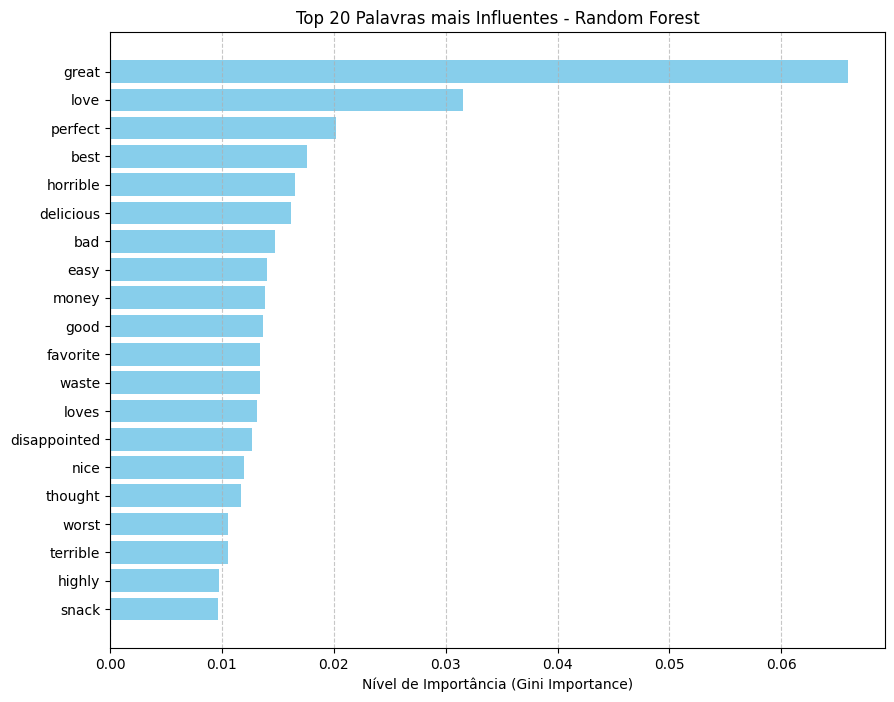

As 5 palavras que mais definem o sentimento nesta árvore:
       Palavra  Importância
1873     great     0.065966
2523      love     0.031532
3116   perfect     0.020179
353       best     0.017585
2073  horrible     0.016577


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Extrair as importâncias e os nomes das palavras (features)
# Usamos o vectorizer que treinou o modelo (tfidf_vec)
importancias = rf_model.feature_importances_
palavras = tfidf_vec.get_feature_names_out()

# 2. Criar um DataFrame para facilitar a manipulação
df_importancia = pd.DataFrame({'Palavra': palavras, 'Importância': importancias})

# 3. Ordenar e selecionar as 20 mais influentes
df_top20 = df_importancia.sort_values(by='Importância', ascending=False).head(20)

# 4. Criar o Gráfico
plt.figure(figsize=(10, 8))
plt.barh(df_top20['Palavra'][::-1], df_top20['Importância'][::-1], color='skyblue')
plt.xlabel('Nível de Importância (Gini Importance)')
plt.title('Top 20 Palavras mais Influentes - Random Forest')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# 5. Print opcional para o relatório
print("As 5 palavras que mais definem o sentimento nesta árvore:")
print(df_top20.head(5))

### Random Forest BOW

In [59]:
from sklearn.ensemble import RandomForestClassifier

# O Random Forest é muito mais robusto
rf_model = RandomForestClassifier(n_estimators=100, max_depth=20, class_weight='balanced', n_jobs=-1)
rf_model.fit(X_train_bow, y_train)

y_pred_rf1 = rf_model.predict(X_test_bow)
print(f"\n{'='*20} RANDOM FOREST (TF-IDF) {'='*20}")
print(classification_report(y_test, y_pred_rf1))


==================== RANDOM FOREST (TF-IDF) ====================
              precision    recall  f1-score   support

    negative       0.69      0.75      0.72       741
    positive       0.89      0.85      0.87      1676

    accuracy                           0.82      2417
   macro avg       0.79      0.80      0.79      2417
weighted avg       0.83      0.82      0.82      2417



### SVM TF-IDF

In [60]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix

# 1. EXPERIÊNCIA: TF-IDF + SVM
# Usamos o class_weight='balanced' para compensar o desequilíbrio do dataset
svm_tfidf = LinearSVC(class_weight='balanced', max_iter=2000, random_state=42)
svm_tfidf.fit(X_train_tfidf, y_train)

y_pred_svm_tfidf = svm_tfidf.predict(X_test_tfidf)

print(f"\n{'='*20} SVM (TF-IDF) {'='*20}")
print(classification_report(y_test, y_pred_svm_tfidf))




==================== SVM (TF-IDF) ====================
              precision    recall  f1-score   support

    negative       0.71      0.82      0.76       741
    positive       0.92      0.85      0.88      1676

    accuracy                           0.84      2417
   macro avg       0.81      0.84      0.82      2417
weighted avg       0.85      0.84      0.84      2417



### SVM BOW

In [61]:
# 2. EXPERIÊNCIA: BAG OF WORDS (BoW) + SVM
svm_bow = LinearSVC(class_weight='balanced', max_iter=2000, random_state=42)
svm_bow.fit(X_train_bow, y_train)

y_pred_svm_bow = svm_bow.predict(X_test_bow)

print(f"\n{'='*20} SVM (BAG OF WORDS) {'='*20}")
print(classification_report(y_test, y_pred_svm_bow))


==================== SVM (BAG OF WORDS) ====================
              precision    recall  f1-score   support

    negative       0.69      0.79      0.74       741
    positive       0.90      0.85      0.87      1676

    accuracy                           0.83      2417
   macro avg       0.80      0.82      0.81      2417
weighted avg       0.84      0.83      0.83      2417



### SVM W2V

In [62]:
from sklearn.svm import LinearSVC

# Usamos os vetores médios (X_train_w2v e X_test_w2v) que criaram anteriormente
svm_w2v = LinearSVC(class_weight='balanced', max_iter=2000, random_state=42)
svm_w2v.fit(X_train_w2v, y_train)

y_pred_svm_w2v = svm_w2v.predict(X_test_w2v)

print(f"\n{'='*20} SVM (WORD2VEC EMBEDDINGS) {'='*20}")
print(classification_report(y_test, y_pred_svm_w2v))


==================== SVM (WORD2VEC EMBEDDINGS) ====================
              precision    recall  f1-score   support

    negative       0.63      0.85      0.73       741
    positive       0.92      0.78      0.85      1676

    accuracy                           0.80      2417
   macro avg       0.78      0.82      0.79      2417
weighted avg       0.83      0.80      0.81      2417



### SVM Gráfico de palavras TF-IDF

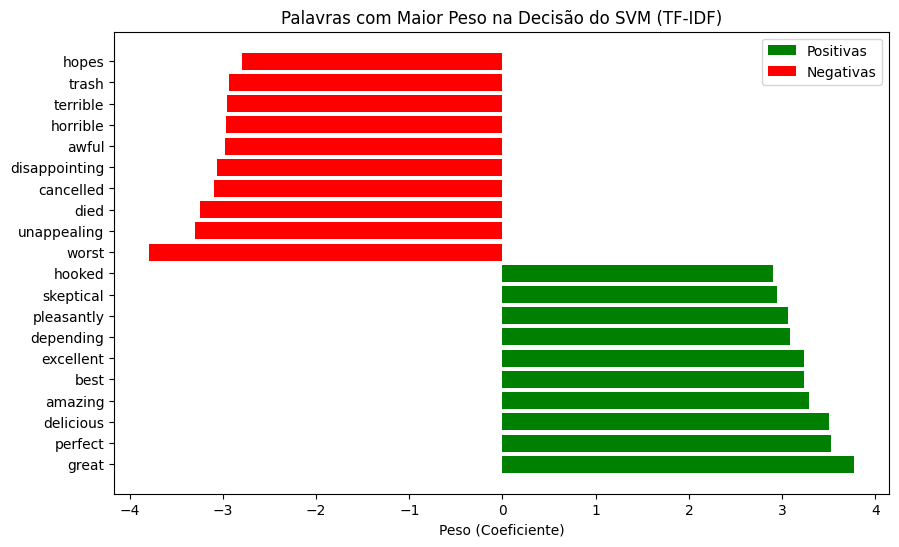

In [63]:
# Extrair pesos das palavras para o SVM com TF-IDF
weights = svm_tfidf.coef_[0]
features = tfidf_vec.get_feature_names_out()

# Criar um DataFrame com os pesos
df_weights = pd.DataFrame({'word': features, 'weight': weights})

# Top 10 Positivas e Top 10 Negativas
top_pos = df_weights.sort_values(by='weight', ascending=False).head(10)
top_neg = df_weights.sort_values(by='weight', ascending=True).head(10)

# Gráfico de barras horizontais
plt.figure(figsize=(10, 6))
plt.barh(top_pos['word'], top_pos['weight'], color='green', label='Positivas')
plt.barh(top_neg['word'], top_neg['weight'], color='red', label='Negativas')
plt.title('Palavras com Maior Peso na Decisão do SVM (TF-IDF)')
plt.xlabel('Peso (Coeficiente)')
plt.legend()
plt.show()

### SVM TF-IDF COM NEG

In [88]:
import nltk
from nltk.sentiment.util import mark_negation
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

# 1. Função de pré-processamento com Negação
def tokenize_neg_clean(text):
    # 1. Limpeza inicial de ruído (Mantemos a pontuação aqui!)
    text = str(text).lower()
    text = re.sub(r'<[^>]+>', ' ', text) # Remove HTML
    text = re.sub(r'http\S+', '', text)  # Remove URLs
    
    # 2. Tokenização (preserva a pontuação para o mark_negation ver)
    tokens = nltk.word_tokenize(text)
    
    # 3. Aplicar Negação (os pontos e vírgulas delimitam o alcance)
    neg_tokens = mark_negation(tokens)
    
    clean_tokens = []
    for t in neg_tokens:
        # t pode ser algo como "good_NEG" ou "!!!" ou "food."
        is_negated = t.endswith('_NEG')
        base_word = t[:-4] if is_negated else t
        
        # 4. Limpeza Restante (Equivalente ao teu re.sub(r'[^a-z\s]', '', text))
        # Removemos pontuação, números e símbolos de cada token
        clean_word = re.sub(r'[^a-z]', '', base_word)
        
        if clean_word: # Se após a limpeza ainda sobrar uma palavra
            # Se for stopword e não for uma palavra de negação crítica, descartamos
            if clean_word in filtered_stopwords and clean_word not in negation_words:
                continue
            
            # Reconstrói o token com o sufixo se ele for negado
            final_token = f"{clean_word}_NEG" if is_negated else clean_word
            clean_tokens.append(final_token)
            
    return clean_tokens

# 2. Nova Vetorização TF-IDF
# Passamos a nossa função como tokenizer. Aumentamos as features para 15k
# porque o vocabulário vai crescer com os termos _NEG.
tfidf_neg = TfidfVectorizer(
    tokenizer=tokenize_neg_clean, 
    token_pattern=None, 
    lowercase=False, # Já feito na função
    max_features=15000
)

print("Vetorizando com tratamento de negação... (Isto pode demorar um pouco)")
X_train_neg = tfidf_neg.fit_transform(df_train['review'])
X_test_neg = tfidf_neg.transform(df_test['review'])

# 3. Treino do SVM (mantendo balanced para lidar com a assimetria)
svm_neg = LinearSVC(class_weight='balanced', max_iter=2000, random_state=42)
svm_neg.fit(X_train_neg, y_train)

# 4. Avaliação
y_pred_neg = svm_neg.predict(X_test_neg)

print(f"\n{'='*20} SVM (TF-IDF + NEGATION) {'='*20}")
print(classification_report(y_test, y_pred_neg))

Vetorizando com tratamento de negação... (Isto pode demorar um pouco)

==================== SVM (TF-IDF + NEGATION) ====================
              precision    recall  f1-score   support

    negative       0.75      0.82      0.78       741
    positive       0.92      0.88      0.90      1676

    accuracy                           0.86      2417
   macro avg       0.83      0.85      0.84      2417
weighted avg       0.87      0.86      0.86      2417



## 2.3.2

In [65]:
%pip install datasets

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [66]:
%pip install accelerate -U
%pip install transformers[torch] -U

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


  Attempting uninstall: transformers
    Found existing installation: transformers 5.5.4
    Uninstalling transformers-5.5.4:
      Successfully uninstalled transformers-5.5.4
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [67]:
import accelerate
print(accelerate.__version__)

1.13.0


In [68]:
import accelerate
import transformers

# Forçar a verificação manual
print(f"Accelerate version: {accelerate.__version__}")
transformers.utils.import_utils._is_accelerate_available = True

Accelerate version: 1.13.0


### DistilBert normal finetuning

In [69]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset
import numpy as np

# 1. Preparar os dados no formato que a Hugging Face espera
# Converter os vossos DataFrames para objetos 'Dataset'
train_dataset = Dataset.from_pandas(df_train[['review_cleaned', 'sentiment']])
test_dataset = Dataset.from_pandas(df_test[['review_cleaned', 'sentiment']])

# Mapear labels para números (ex: positive -> 1, negative -> 0)
label_map = {"positive": 1, "negative": 0}
def tokenize_function(examples):
    tokens = tokenizer(examples["review_cleaned"], padding="max_length", truncation=True)
    tokens["labels"] = [label_map[l] for l in examples["sentiment"]]
    return tokens

# 2. Carregar Tokenizer e Model
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

# Tokenizar os datasets
train_tokenized = train_dataset.map(tokenize_function, batched=True)
test_tokenized = test_dataset.map(tokenize_function, batched=True)

# 3. Configurações de Treino (Onde controlam os recursos)
# 3. Configurações de Treino atualizadas
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",      # <--- Mudou de evaluation_strategy para eval_strategy
    learning_rate=2e-5,
    per_device_train_batch_size=16, 
    num_train_epochs=3,             
    weight_decay=0.01,
    logging_dir='./logs',
    fp16=True,                  # Se tens GPU CUDA, isto vai acelerar muito
)
# 4. Inicializar o Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
)

# 5. TREINAR (Atenção: Isto vai demorar)
trainer.train()

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 5013.63it/s]
DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Map: 100%|██████████| 2417/2417 [00:00<00:00, 2434.68 examples/s]
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` inste

Epoch,Training Loss,Validation Loss
1,0.199464,0.202240
2,0.138569,0.206561
3,0.078060,0.309231


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.99it/s]


TrainOutput(global_step=9171, training_loss=0.15437778081489406, metrics={'train_runtime': 1426.8209, 'train_samples_per_second': 102.82, 'train_steps_per_second': 6.428, 'total_flos': 1.9433762187227136e+16, 'train_loss': 0.15437778081489406, 'epoch': 3.0})

In [70]:
# 1. Obter as previsões do modelo no conjunto de teste
# O 'predictions' devolve os logits (valores brutos antes da ativação)
raw_pred, _, _ = trainer.predict(test_tokenized)

# 2. Aplicar Argmax para obter a classe com maior probabilidade (0 ou 1)
y_pred_indices = np.argmax(raw_pred, axis=1)

# 3. Converter índices de volta para as labels originais ('positive', 'negative')
# Lembra-te que definimos: {"positive": 1, "negative": 0}
inv_label_map = {1: 'positive', 0: 'negative'}
df_test['pred_distilbert_finetuned'] = [inv_label_map[p] for p in y_pred_indices]

# 4. Gerar Relatório de Classificação
from sklearn.metrics import classification_report, confusion_matrix
print(f"\n{'='*20} DISTILBERT FINE-TUNED {'='*20}")
print(classification_report(df_test['sentiment'], df_test['pred_distilbert_finetuned']))

# 5. Gerar Matriz de Confusão para o relatório
cm_bert = confusion_matrix(df_test['sentiment'], df_test['pred_distilbert_finetuned'], labels=['positive', 'negative'])
print("Matriz de Confusão:")
print(cm_bert)


==================== DISTILBERT FINE-TUNED ====================
              precision    recall  f1-score   support

    negative       0.90      0.84      0.87       741
    positive       0.93      0.96      0.94      1676

    accuracy                           0.92      2417
   macro avg       0.91      0.90      0.90      2417
weighted avg       0.92      0.92      0.92      2417

Matriz de Confusão:
[[1604   72]
 [ 121  620]]


### DistilBert SST2 finetuning

In [71]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset
import numpy as np

# 1. Preparar os dados (mantemos os mesmos datasets já tokenizados se preferires, 
# mas por segurança vamos definir o mapeamento)
label_map = {"positive": 1, "negative": 0}

# 2. Carregar Tokenizer e Model ESPECÍFICO (SST-2)
# Usamos nomes de variáveis diferentes (ex: tokenizer_sst2) para não apagar os anteriores na memória
model_sst2_name = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer_sst2 = AutoTokenizer.from_pretrained(model_sst2_name)
model_sst2 = AutoModelForSequenceClassification.from_pretrained(model_sst2_name, num_labels=2)

def tokenize_function_sst2(examples):
    tokens = tokenizer_sst2(examples["review_cleaned"], padding="max_length", truncation=True)
    tokens["labels"] = [label_map[l] for l in examples["sentiment"]]
    return tokens

# Criar novos datasets tokenizados específicos para este modelo
train_tokenized_sst2 = train_dataset.map(tokenize_function_sst2, batched=True)
test_tokenized_sst2 = test_dataset.map(tokenize_function_sst2, batched=True)

# 3. Configurações de Treino (Caminhos de saída diferentes!)
training_args_sst2 = TrainingArguments(
    output_dir="./results_distilbert_sst2", 
    eval_strategy="epoch",
    learning_rate=1e-5,                     # LR mais baixa para não destruir o fine-tuning prévio
    per_device_train_batch_size=16, 
    num_train_epochs=3, 
    weight_decay=0.01,
    logging_dir='./logs_sst2',              # Logs separados para o TensorBoard
    fp16=True,
    run_name="distilbert-sst2-finetuning"   # Nome da experiência
)

# 4. Inicializar o NOVO Trainer
trainer_sst2 = Trainer(
    model=model_sst2,
    args=training_args_sst2,
    train_dataset=train_tokenized_sst2,
    eval_dataset=test_tokenized_sst2,
)

# 5. TREINAR
print("A iniciar o treino do modelo especializado (SST-2)...")
trainer_sst2.train()

# 6. Avaliar e guardar resultados separadamente
results_sst2 = trainer_sst2.evaluate()
print(f"Resultados SST-2: {results_sst2}")

Map: 100%|██████████| 2417/2417 [00:00<00:00, 2440.20 examples/s]
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


A iniciar o treino do modelo especializado (SST-2)...


Epoch,Training Loss,Validation Loss
1,0.201252,0.231135
2,0.154404,0.227718
3,0.115812,0.292781


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.57it/s]


Training Loss,Validation Loss,Epoch
0.115812,0.292781,3


Resultados SST-2: {'eval_loss': 0.2927806079387665}


In [76]:
# 1. Obter as previsões do modelo no conjunto de teste
# O 'predictions' devolve os logits (valores brutos antes da ativação)
raw_pred1, _, _ = trainer_sst2.predict(test_tokenized_sst2)

# 2. Aplicar Argmax para obter a classe com maior probabilidade (0 ou 1)
y_pred_indices1 = np.argmax(raw_pred1, axis=1)

# 3. Converter índices de volta para as labels originais ('positive', 'negative')
# Lembra-te que definimos: {"positive": 1, "negative": 0}
inv_label_map = {1: 'positive', 0: 'negative'}
df_test['pred_distilbert_sst2_finetuned'] = [inv_label_map[p] for p in y_pred_indices1]

# 4. Gerar Relatório de Classificação
from sklearn.metrics import classification_report, confusion_matrix
print(f"\n{'='*20} DISTILBERT SST2 FINE-TUNED {'='*20}")
print(classification_report(df_test['sentiment'], df_test['pred_distilbert_sst2_finetuned']))

# 5. Gerar Matriz de Confusão para o relatório
cm_bert1 = confusion_matrix(df_test['sentiment'], df_test['pred_distilbert_sst2_finetuned'], labels=['positive', 'negative'])
print("Matriz de Confusão:")
print(cm_bert1)


==================== DISTILBERT SST2 FINE-TUNED ====================
              precision    recall  f1-score   support

    negative       0.88      0.83      0.86       741
    positive       0.93      0.95      0.94      1676

    accuracy                           0.91      2417
   macro avg       0.91      0.89      0.90      2417
weighted avg       0.91      0.91      0.91      2417

Matriz de Confusão:
[[1595   81]
 [ 125  616]]


## Nuvens de palavras

In [72]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the '~\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


### Só df_teste

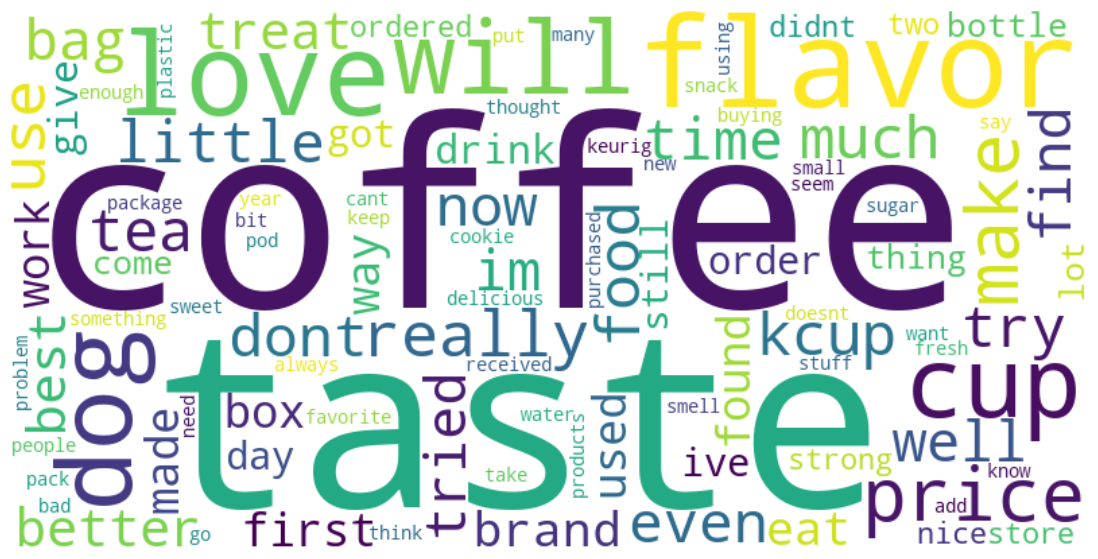

In [ ]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# 1. Preparar as stopwords
# Usamos as do WordCloud e podemos adicionar palavras "vazias" típicas da Amazon
stop_words = set(STOPWORDS)
stop_words.update(['amazon', 'product', 'review', 'buy', 'bought', 'one', 'good', 'great'])

# 2. Juntar todas as reviews num único texto gigante
# Filtramos apenas as reviews positivas ou todas, conforme preferires
text = " ".join(review for review in df_test.review_cleaned.astype(str))

# 3. Gerar a nuvem
wordcloud = WordCloud(
    width=800, 
    height=400,
    background_color='white',
    stopwords=stop_words,
    max_words=100,
    colormap='viridis', # Cores bonitas
    contour_width=1,
    contour_color='steelblue'
).generate(text)

# 4. Mostrar o gráfico
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off") # Esconder os eixos
plt.show()

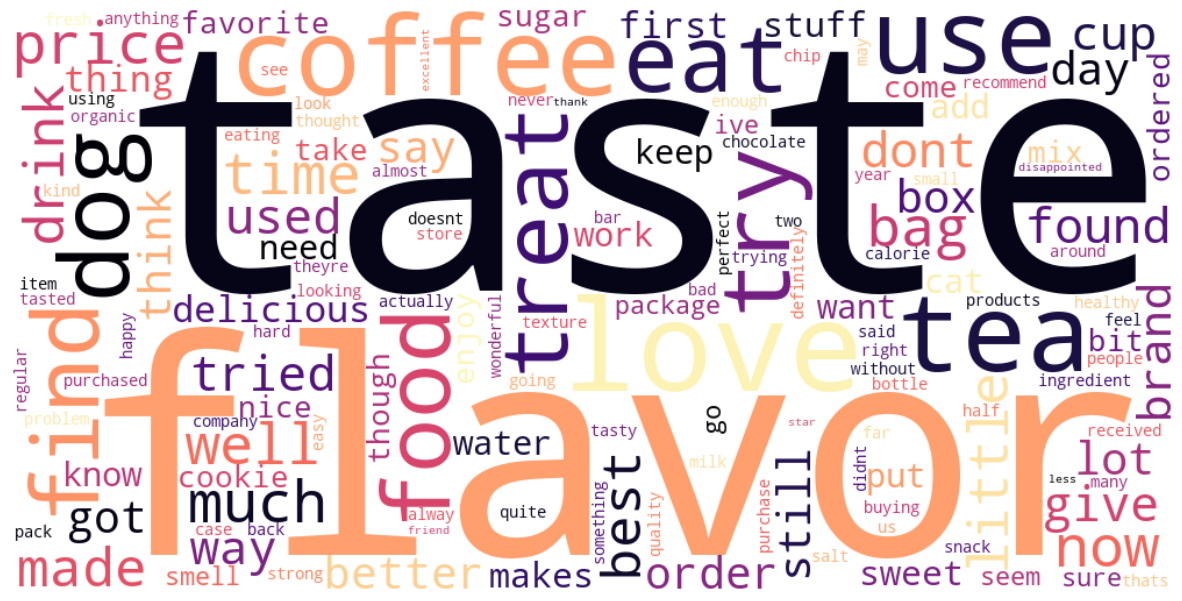

In [74]:
import pandas as pd
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# 1. Juntar as reviews de treino e teste
all_reviews = pd.concat([df_train['review_cleaned'], df_test['review_cleaned']])
text_total = " ".join(review for review in all_reviews.astype(str))

# 2. Stopwords (e palavras que apareçam muito mas não digam nada)
stop_words = set(STOPWORDS)
stop_words.update(['amazon', 'product', 'review', 'buy', 'bought', 'one', 'good', 'great', 'really','will', 'im', 'even', 'make', 'u'])

# 3. Gerar a nuvem do TOTAL
wordcloud_total = WordCloud(
    width=1000, 
    height=500,
    background_color='white',
    stopwords=stop_words,
    max_words=150, # Aumentei um pouco para o total
    colormap='magma'
).generate(text_total)

plt.figure(figsize=(15, 8))
plt.imshow(wordcloud_total, interpolation='bilinear')
plt.axis("off")
plt.show()